# P501 FFT overlay example

Loads the `p501_fft` overlay (the P501 base design plus a streaming FFT on the AD9361 ADC data), transmits a tone from TX1,
and reads FFT frames **computed in the FPGA** through a DMA. The spectrum is plotted and cross-checked against NumPy's FFT of a raw
ADC capture taken at the same time.

**Before you start**
1. Build the overlay with `create_project.tcl` (see the README), run `tools/fix_hwh.py` on the `.hwh`, and copy
   `p501_fft.bit` and `p501_fft.hwh` to `/home/xilinx/jupyter_notebooks/p501_fft/` on the board.
2. TX1 and RX1 antennas near each other (or a cable with at least 40 dB attenuation - never connect them directly).
3. Run the cells top to bottom; each check prints `PASS` / `FAIL`.

## 0. Configuration

In [1]:
BIT       = "/home/xilinx/jupyter_notebooks/p501_fft/p501_fft.bit"   # overlay built by create_project.tcl
NFFT_LOG2 = 10                 # must equal NFFT_LOG2 used to build the overlay
SCALE_SHIFT = NFFT_LOG2 - 4    # must equal SCALE_SHIFT used to build the overlay (default: NFFT_LOG2 - 4)
N         = 1 << NFFT_LOG2     # FFT length
FS        = 3_840_000          # sample rate (3.84 MSPS preset of the AD9361 driver)
LO        = 700_000_000        # RF centre frequency, Hz
RF_BW     = 4_000_000          # analog bandwidth, Hz
TONE_BIN  = 267                # transmit a tone exactly on this FFT bin (frequency = bin * FS / N)
FRAMES    = 64                 # FFT frames read per DMA transfer
TX_ATTEN  = 10                 # dB
RX_GAIN   = 45                 # gain-table index 0..76
SETTLE_DB = 45                 # image rejection the AD9361 bring-up waits for (see P501_AD9361_Test.ipynb)

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
from ad9361_driver import (AD9361, FIR_RX1, FIR_TX1,
                           REG_ENSM_CONFIG_1, TO_ALERT, FORCE_ALERT_STATE)
from axi_dmac import AxiDmac
import ad9361_full_bypass_test as fb
from ad9361_fir_test import make_fir_coef

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol   = Overlay(BIT)                              # loads the bitstream with the FFT chain
txd  = AxiDmac(ol.axi_ad9361_dac_dma)            # TX samples  (existing ADI DMA)
rxd  = AxiDmac(ol.axi_ad9361_adc_dma)            # raw ADC capture (existing ADI DMA)
fftd = AxiDmac(ol.fft_dma)                       # FFT output   (new DMA with an AXI-Stream source)
print("IPs in the overlay:", sorted(k for k in ol.ip_dict if k.startswith(("fft", "axi_ad9361"))))

IPs in the overlay: ['axi_ad9361', 'axi_ad9361_adc_dma', 'axi_ad9361_dac_dma', 'fft_dma']


## 1. AD9361 bring-up

Exactly the software flow of `P501_AD9361_Test.ipynb`: the AD9361 is configured over SPI, the FPGA side only needs the core enable
and the DAC data rate. Only the overlay is different.

In [3]:
M_TX = 8192                                       # samples in the TX loop buffer

def tone_buffer_bin(k):
    """Complex tone exactly on FFT bin k of the N-point FFT (whole cycles in the TX buffer, no leakage)."""
    cycles = k * (M_TX // N)
    t = np.exp(2j * np.pi * cycles * np.arange(M_TX) / M_TX) * 0.5 * (2**15 - 1)
    tx = allocate(shape=(M_TX * 2,), dtype=np.int16)
    tx[0::2] = t.real.astype(np.int16)
    tx[1::2] = t.imag.astype(np.int16)
    tx.flush()
    return tx, k * FS / N

def capture_adc(n=8192, tx=None):
    rx = allocate(shape=(n * 2,), dtype=np.int16)
    ok = rxd.transfer_to_memory(rx.physical_address, rx.nbytes)
    rx.invalidate()
    a = np.array(rx); rx.freebuffer()
    return ok, a[0::2].astype(float) + 1j * a[1::2].astype(float)

def settle(ad, min_rej_db=SETTLE_DB, max_tries=40):
    """Re-enable the chip until the image rejection of a test tone is good (known AD9361 analog-state issue)."""
    tx, f = tone_buffer_bin(TONE_BIN)
    freqs = np.fft.fftshift(np.fft.fftfreq(8192, 1 / FS))
    for tries in range(1, max_tries + 1):
        txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)
        ok, x = capture_adc()
        txd.stop()
        x = x - x.mean()
        m = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * np.hanning(len(x))))) + 1e-9)
        sel = lambda f0: m[np.abs(freqs - f0) < 25e3].max()
        rej = sel(f) - sel(-f)
        if rej >= min_rej_db:
            break
        ad.reg_write(REG_ENSM_CONFIG_1, TO_ALERT | FORCE_ALERT_STATE)
        if tries % 8 == 0:
            ad.tx_quad_calib(RF_BW // 2, RF_BW // 2)
        ad.enable_fdd()
        fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    tx.freebuffer()
    return rej, tries

try:
    ad.close()
except NameError:
    pass
ad = AD9361()
ad.power_up_clocks()
assert ad.set_bbpll_rate(983_040_000), "BBPLL did not lock"
ad.set_clock_chain()                                          # 3.84 MSPS
ad.synth_cp_calib(False); ad.synth_cp_calib(True)
rx_ok = ad.set_rx_lo_freq(LO); tx_ok = ad.set_tx_lo_freq(LO)
ad.enable_rx1_tx1()
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_1, fb.PP_CONF_1)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_2, fb.PP_CONF_2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_3, fb.PP_CONF_3_LVDS_MODE)
ad.reg_write(fb.REG_RX_CLOCK_DATA_DELAY, fb.RX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_TX_CLOCK_DATA_DELAY, fb.TX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_LVDS_BIAS_CTRL, fb.LVDS_BIAS_CTRL)
cal = ad.analog_init(rf_rx_bw_hz=RF_BW, rf_tx_bw_hz=RF_BW, rx_freq_hz=LO)
ad.set_rx_manual_gain(RX_GAIN)
ad.set_tx_atten_db(TX_ATTEN)
ad.enable_fdd()
coef = make_fir_coef()
ad.load_fir_filter_coef(FIR_RX1, 0, coef)
ad.load_fir_filter_coef(FIR_TX1, 0, coef)
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
rej, tries = settle(ad)
print(f"product id 0x{ad.product_id():02X}, ENSM 0x{ad.ensm_state():X}, LO locks {rx_ok}/{tx_ok}, settled after {tries} tries ({rej:.1f} dB image rejection)")
check("AD9361 up", ad.product_id_ok() and rx_ok and tx_ok and ad.ensm_state() == 0xA, f"calibrations {cal}")

product id 0x0A, ENSM 0xA, LO locks True/True, settled after 3 tries (45.2 dB image rejection)
PASS  AD9361 up: calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## 2. Hardware FFT

Start the TX tone, then program the FFT DMA for `FRAMES` frames of `N` 32-bit power values (`|X|^2`). The DMA only accepts frames
while a transfer is running, and always starts on a frame boundary.

In [4]:
tx, f_tone = tone_buffer_bin(TONE_BIN)
txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)      # tone on, looping

hw = allocate(shape=(FRAMES, N), dtype=np.uint32)
ok_fft = fftd.transfer_to_memory(hw.physical_address, hw.nbytes, timeout_s=5.0)
hw.invalidate()
P_hw = np.array(hw, dtype=np.float64)                                      # (FRAMES, N) power per bin, natural order
hw.freebuffer()

ok_raw, x_raw = capture_adc(8192)                                          # raw ADC samples for the NumPy reference
txd.stop(); tx.freebuffer()
print(f"{FRAMES} frames x {N} bins read; max value {P_hw.max():.3g} (int32 limit 2^31 = {2**31:.3g})")

64 frames x 1024 bins read; max value 4.18e+06 (int32 limit 2^31 = 2.15e+09)


## 3. Plots and cross-check

*Hardware*: mean of the `FRAMES` frames. *Reference*: NumPy FFT of the raw ADC samples, same length, rectangular window, scaled by
`2^-SCALE_SHIFT` per amplitude (the FPGA divides by `2^SCALE_SHIFT` inside the FFT). The two should agree on the tone and the
spectrum shape; the noise floor of the hardware result is limited by its 16-bit output.

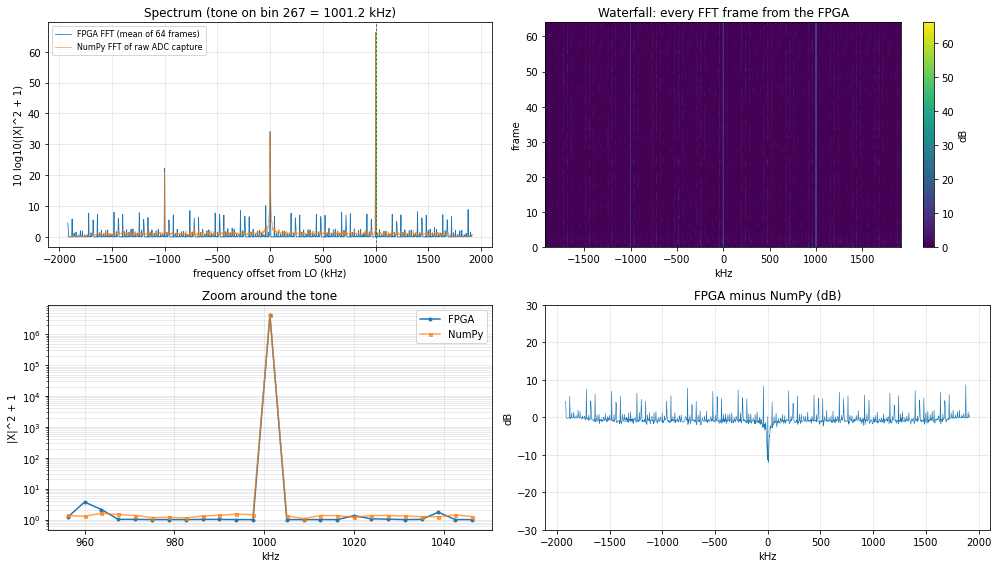

PASS  FFT DMA: frames and raw capture completed
PASS  peak on the transmitted bin: hardware peak at bin 267, tone on bin 267
PASS  tone above floor: 66.1 dB above the median floor
PASS  matches NumPy at the tone: hardware / reference = +0.00 dB
PASS  no overflow: max power 4.18e+06


In [5]:
f_axis = np.fft.fftshift(np.fft.fftfreq(N, 1 / FS)) / 1e3                  # kHz
hw_avg = np.fft.fftshift(P_hw.mean(axis=0))
blocks = x_raw[: (len(x_raw) // N) * N].reshape(-1, N)
ref_avg = np.fft.fftshift((np.abs(np.fft.fft(blocks, axis=1)) ** 2).mean(axis=0)) / 4.0 ** SCALE_SHIFT
db = lambda p: 10 * np.log10(p + 1.0)

k_peak = int(np.argmax(hw_avg)) - N // 2                                   # bin number relative to DC
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(f_axis, db(hw_avg), lw=0.8, label="FPGA FFT (mean of %d frames)" % FRAMES)
ax[0, 0].plot(f_axis, db(ref_avg), lw=0.8, alpha=0.7, label="NumPy FFT of raw ADC capture")
ax[0, 0].axvline(f_tone / 1e3, color="g", ls="--", lw=0.8)
ax[0, 0].set(title=f"Spectrum (tone on bin {TONE_BIN} = {f_tone/1e3:.1f} kHz)", xlabel="frequency offset from LO (kHz)", ylabel="10 log10(|X|^2 + 1)")
ax[0, 0].legend(fontsize=8); ax[0, 0].grid(alpha=.3)

im = ax[0, 1].imshow(db(np.fft.fftshift(P_hw, axes=1)), aspect="auto", origin="lower", cmap="viridis",
                     extent=[f_axis[0], f_axis[-1], 0, FRAMES])
ax[0, 1].set(title="Waterfall: every FFT frame from the FPGA", xlabel="kHz", ylabel="frame")
fig.colorbar(im, ax=ax[0, 1], label="dB")

lo, hi = N // 2 + TONE_BIN - 12, N // 2 + TONE_BIN + 13
ax[1, 0].semilogy(f_axis[lo:hi], hw_avg[lo:hi] + 1, "o-", ms=3, label="FPGA")
ax[1, 0].semilogy(f_axis[lo:hi], ref_avg[lo:hi] + 1, "s-", ms=3, alpha=0.7, label="NumPy")
ax[1, 0].set(title="Zoom around the tone", xlabel="kHz", ylabel="|X|^2 + 1"); ax[1, 0].legend(); ax[1, 0].grid(alpha=.3, which="both")

ax[1, 1].plot(f_axis, db(hw_avg) - db(ref_avg), lw=0.6)
ax[1, 1].set(title="FPGA minus NumPy (dB)", xlabel="kHz", ylabel="dB", ylim=(-30, 30)); ax[1, 1].grid(alpha=.3)
plt.tight_layout(); plt.show()

floor_db = float(np.median(db(hw_avg)))
ratio_db = 10 * np.log10((hw_avg[N // 2 + TONE_BIN] + 1) / (ref_avg[N // 2 + TONE_BIN] + 1))
check("FFT DMA", ok_fft and ok_raw, "frames and raw capture completed")
check("peak on the transmitted bin", abs(k_peak - TONE_BIN) <= 1, f"hardware peak at bin {k_peak}, tone on bin {TONE_BIN}")
check("tone above floor", db(hw_avg[N // 2 + TONE_BIN]) - floor_db > 30, f"{db(hw_avg[N // 2 + TONE_BIN]) - floor_db:.1f} dB above the median floor")
check("matches NumPy at the tone", abs(ratio_db) < 3, f"hardware / reference = {ratio_db:+.2f} dB")
check("no overflow", P_hw.max() < 2**31 - 1, f"max power {P_hw.max():.3g}")

## 4. Summary

In [6]:
width = max(len(k) for k in results)
for name, (ok, detail) in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name:<{width}}  {detail}")
print()
print("ALL TESTS PASSED" if all(ok for ok, _ in results.values()) else "SOME TESTS FAILED - see above")
ad.close()

PASS  AD9361 up                    calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}
PASS  FFT DMA                      frames and raw capture completed
PASS  peak on the transmitted bin  hardware peak at bin 267, tone on bin 267
PASS  tone above floor             66.1 dB above the median floor
PASS  matches NumPy at the tone    hardware / reference = +0.00 dB
PASS  no overflow                  max power 4.18e+06

ALL TESTS PASSED


### Ideas to extend

* Change `NFFT_LOG2` / `SCALE_SHIFT` in `create_project.tcl`, rebuild, and set the same values in section 0.
* Add a Hann window before the FFT, average K frames in hardware, decimate for a zoom FFT - see `bd/fft_chain.tcl`.
* For two receive channels build a second chain from `adc_data_i1`/`adc_valid_i1` (2R2T).